# Single-period Brinson attribution and reports

Use one monthly period from the local synthetic Dow 30 portfolio. This tutorial calls only the **single-period** calculation and reporting interfaces. Returns and effects are decimal values; charts convert them to percentage or basis points.

## 1. Load the local data

The CSV inputs are in `data/dow30_brinson/`. Start Jupyter from the repository root or either language tutorial folder.

In [1]:
from pathlib import Path
import sys
import polars as pl
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "brinsons").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Launch Jupyter from the project root or tutorials/.")
sys.path.insert(0, str(ROOT / "src"))
from brinsons import (
    ColumnNames, bhb, fachler, calculate_single_period,
    print_single_period_category_weights, print_single_period_category_returns,
    print_single_period_category_attribution, print_single_period_total_attribution,
    print_single_period_attribution_summary, chart_single_period_category_returns,
    chart_single_period_category_weights, chart_single_period_category_attribution,
    chart_single_period_excess_return_waterfall,
)

asset = pl.read_csv(ROOT / "data" / "dow30_brinson" / "asset_table.csv")
periods = pl.read_csv(ROOT / "data" / "dow30_brinson" / "periods.csv")
print(f"{asset['Name'].n_unique()} stocks, {periods.height} monthly periods")
display(asset.head(6))

30 stocks, 12 monthly periods


Period,Name,Return,Category,PortfolioWeight,BenchmarkWeight
i64,str,f64,str,f64,f64
1,"""AAPL""",0.061815,"""Technology""",0.032875,0.033333
1,"""AMGN""",0.057512,"""Healthcare""",0.030001,0.033333
1,"""AMZN""",0.112265,"""Consumer Cyclical""",0.031268,0.033333
1,"""AXP""",0.088764,"""Financial Services""",0.035456,0.033333
1,"""BA""",-0.068619,"""Industrials""",0.034092,0.033333
1,"""CAT""",0.213284,"""Industrials""",0.036527,0.033333


## 2. Build sector returns without changing the input column names

Aggregate asset weights and weighted returns by period and sector. `ColumnNames` tells `brinsons` which original columns to read.

In [2]:
sector = asset.group_by(["Period", "Category"]).agg(
    pl.col("PortfolioWeight", "BenchmarkWeight").sum(),
    (pl.col("PortfolioWeight") * pl.col("Return")).sum().alias("PortfolioContribution"),
    (pl.col("BenchmarkWeight") * pl.col("Return")).sum().alias("BenchmarkContribution"),
).with_columns(
    (pl.col("PortfolioContribution") / pl.col("PortfolioWeight")).alias("PortfolioReturn"),
    (pl.col("BenchmarkContribution") / pl.col("BenchmarkWeight")).alias("BenchmarkReturn"),
).sort(["Period", "Category"])
column_names = ColumnNames(period="Period", segment="Category",
    portfolio_weight="PortfolioWeight", benchmark_weight="BenchmarkWeight",
    portfolio_return="PortfolioReturn", benchmark_return="BenchmarkReturn")
display(sector.head())

Period,Category,PortfolioWeight,BenchmarkWeight,PortfolioContribution,BenchmarkContribution,PortfolioReturn,BenchmarkReturn
i64,str,f64,f64,f64,f64,f64,f64
1,"""Basic Materials""",0.022769,0.033333,-0.000087,-0.000127,-0.003812,-0.003812
1,"""Communication Services""",0.069037,0.066667,0.005063,0.004676,0.073338,0.070133
1,"""Consumer Cyclical""",0.119859,0.133333,-0.001293,-0.00142,-0.010789,-0.010649
1,"""Consumer Defensive""",0.087666,0.1,0.000361,0.000205,0.004122,0.002052
1,"""Energy""",0.023962,0.033333,0.000375,0.000522,0.015648,0.015648


## 3. Calculate one period

Select period 1 explicitly. For Brinson–Fachler with three effects,
$A_i=(w_{P,i}-w_{B,i})(r_{B,i}-R_B)$,
$S_i=w_{B,i}(r_{P,i}-r_{B,i})$ and
$I_i=(w_{P,i}-w_{B,i})(r_{P,i}-r_{B,i})$.
The three totals reconcile to $R_P-R_B$.

In [3]:
result = calculate_single_period(sector, period=1, attribution=fachler,
                                 effects=3, columns=column_names)
display(result.summary)
display(result.detail.head())

Period,allocation,selection,interaction,portfolio_return,benchmark_return,excess_return
i64,f64,f64,f64,f64,f64,f64
1,0.002055,0.000609,-0.000096,0.031872,0.029305,0.002568


Period,Category,PortfolioWeight,BenchmarkWeight,PortfolioContribution,BenchmarkContribution,PortfolioReturn,BenchmarkReturn,allocation,selection,interaction,portfolio_contribution,benchmark_contribution
i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""Basic Materials""",0.022769,0.033333,-0.000087,-0.000127,-0.003812,-0.003812,0.00035,0.0,-0.0,-0.000087,-0.000127
1,"""Communication Services""",0.069037,0.066667,0.005063,0.004676,0.073338,0.070133,0.000097,0.000214,0.000008,0.005063,0.004676
1,"""Consumer Cyclical""",0.119859,0.133333,-0.001293,-0.00142,-0.010789,-0.010649,0.000538,-0.000019,0.000002,-0.001293,-0.00142
1,"""Consumer Defensive""",0.087666,0.1,0.000361,0.000205,0.004122,0.002052,0.000336,0.000207,-0.000026,0.000361,0.000205
1,"""Energy""",0.023962,0.033333,0.000375,0.000522,0.015648,0.015648,0.000128,0.0,-0.0,0.000375,0.000522


## 4. Compare BHB/BF and two-/three-effect conventions

BHB uses the sector benchmark return as allocation reference; BF subtracts the total benchmark return. Two-effect selection absorbs interaction.

In [4]:
single_method_rows = []
single_category_parts = []
for brinson_name, brinson_fn in [("BHB", bhb), ("BF", fachler)]:
    for effect_count in (2, 3):
        run = calculate_single_period(sector, period=1, attribution=brinson_fn,
                                      effects=effect_count, columns=column_names)
        names = run.columns
        totals = run.summary.row(0, named=True)
        single_method_rows.append({
            "Brinson": brinson_name, "Effects": effect_count,
            "Portfolio (bp)": 10_000 * totals[names.summary_portfolio_return],
            "Benchmark (bp)": 10_000 * totals[names.summary_benchmark_return],
            "Active (bp)": 10_000 * totals[names.summary_excess_return],
            "Allocation (bp)": 10_000 * totals[names.summary_allocation],
            "Selection (bp)": 10_000 * totals[names.summary_selection],
            "Interaction (bp)": 10_000 * totals[names.summary_interaction],
            "Residual (bp)": 10_000 * (
                totals[names.summary_allocation] + totals[names.summary_selection]
                + totals[names.summary_interaction] - totals[names.summary_excess_return]),
        })
        single_category_parts.append(run.detail.select(
            pl.lit(brinson_name).alias("Brinson"),
            pl.lit(effect_count).alias("Effects"),
            pl.col(names.segment).alias("Category"),
            (10_000 * pl.col(names.allocation)).alias("Allocation (bp)"),
            (10_000 * pl.col(names.selection)).alias("Selection (bp)"),
            (10_000 * pl.col(names.interaction)).alias("Interaction (bp)"),
        ))

single_method_comparison = pl.DataFrame(single_method_rows)
single_category_comparison = pl.concat(single_category_parts).sort(["Category", "Brinson", "Effects"])
assert single_method_comparison["Residual (bp)"].abs().max() < 1e-6
with pl.Config(tbl_rows=100, tbl_cols=12, tbl_width_chars=180, fmt_str_lengths=32):
    display(single_method_comparison)
    display(single_category_comparison)


Brinson,Effects,Portfolio (bp),Benchmark (bp),Active (bp),Allocation (bp),Selection (bp),Interaction (bp),Residual (bp)
str,i64,f64,f64,f64,f64,f64,f64,f64
"""BHB""",2,318.724038,293.047339,25.676699,20.550687,5.126012,0.0,0.0
"""BHB""",3,318.724038,293.047339,25.676699,20.550687,6.087469,-0.961457,4.3368e-15
"""BF""",2,318.724038,293.047339,25.676699,20.550687,5.126012,0.0,0.0
"""BF""",3,318.724038,293.047339,25.676699,20.550687,6.087469,-0.961457,0.0


Brinson,Effects,Category,Allocation (bp),Selection (bp),Interaction (bp)
str,i32,str,f64,f64,f64
"""BF""",2,"""Basic Materials""",3.498658,0.0,0.0
"""BF""",3,"""Basic Materials""",3.498658,0.0,-0.0
"""BHB""",2,"""Basic Materials""",0.402744,0.0,0.0
"""BHB""",3,"""Basic Materials""",0.402744,0.0,-0.0
"""BF""",2,"""Communication Services""",0.967714,2.213064,0.0
"""BF""",3,"""Communication Services""",0.967714,2.137083,0.075981
"""BHB""",2,"""Communication Services""",1.662303,2.213064,0.0
"""BHB""",3,"""Communication Services""",1.662303,2.137083,0.075981
"""BF""",2,"""Consumer Cyclical""",5.383578,-0.167528,0.0


### Sector allocation comparison

The aggregate allocation can match even when individual sector allocation differs.

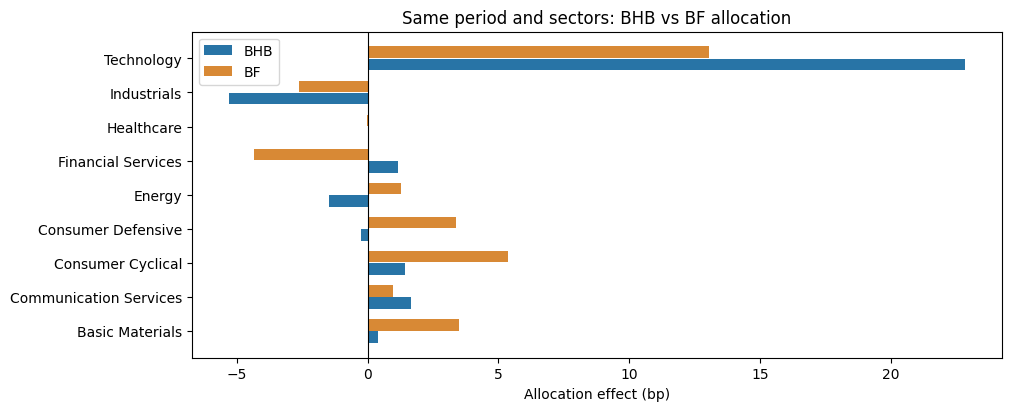

In [5]:
bhb_allocation = single_category_comparison.filter(
    (pl.col("Brinson") == "BHB") & (pl.col("Effects") == 3)).sort("Category")
bf_allocation = single_category_comparison.filter(
    (pl.col("Brinson") == "BF") & (pl.col("Effects") == 3)).sort("Category")
categories = bhb_allocation["Category"].to_list()
assert categories == bf_allocation["Category"].to_list()
positions = list(range(len(categories)))
fig, ax = plt.subplots(figsize=(10, max(4, 0.42 * len(categories))), layout="constrained")
ax.barh([p - 0.18 for p in positions], bhb_allocation["Allocation (bp)"].to_list(),
        height=0.34, label="BHB", color="#2874a6")
ax.barh([p + 0.18 for p in positions], bf_allocation["Allocation (bp)"].to_list(),
        height=0.34, label="BF", color="#d88935")
ax.set_yticks(positions, categories)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Allocation effect (bp)")
ax.set_title("Same period and sectors: BHB vs BF allocation")
ax.legend()
plt.show()


## 5. Category weights

All functions below take the explicit single period `period=1`.

In [6]:
print_single_period_category_weights(result, period=1);

### Category Weights — Period 1

Active weight = portfolio weight − benchmark weight. Across all periods, weights are simple period averages.

| Category | Portfolio | Benchmark | Active |
| --- | --- | --- | --- |
| Basic Materials | 2.2769% | 3.3333% | -1.0565% |
| Communication Services | 6.9037% | 6.6667% | 0.2370% |
| Consumer Cyclical | 11.9859% | 13.3333% | -1.3475% |
| Consumer Defensive | 8.7666% | 10.0000% | -1.2334% |
| Energy | 2.3962% | 3.3333% | -0.9371% |
| Financial Services | 18.5462% | 16.6667% | 1.8795% |
| Healthcare | 13.3642% | 13.3333% | 0.0308% |
| Industrials | 12.4193% | 13.3333% | -0.9140% |
| Technology | 23.3410% | 20.0000% | 3.3410% |

## 6. Category returns

In [7]:
print_single_period_category_returns(result, period=1);

### Category Returns — Period 1

Across all periods, category returns compound period category returns; within-category weights reset each period.

| Category | Portfolio | Benchmark |
| --- | --- | --- |
| Basic Materials | -0.3812% | -0.3812% |
| Communication Services | 7.3338% | 7.0133% |
| Consumer Cyclical | -1.0789% | -1.0649% |
| Consumer Defensive | 0.4122% | 0.2052% |
| Energy | 1.5648% | 1.5648% |
| Financial Services | 0.6125% | 0.6259% |
| Healthcare | 2.0955% | 2.2428% |
| Industrials | 6.2816% | 5.8098% |
| Technology | 6.7329% | 6.8347% |

## 7. Category attribution

In [8]:
print_single_period_category_attribution(result, period=1);

### Category Attribution — Period 1

Allocation + selection + interaction = active contribution.

| Category | Allocation | Selection | Interaction | Active |
| --- | --- | --- | --- | --- |
| Basic Materials | 0.0350% | 0.0000% | -0.0000% | 0.0350% |
| Communication Services | 0.0097% | 0.0214% | 0.0008% | 0.0318% |
| Consumer Cyclical | 0.0538% | -0.0019% | 0.0002% | 0.0522% |
| Consumer Defensive | 0.0336% | 0.0207% | -0.0026% | 0.0518% |
| Energy | 0.0128% | 0.0000% | -0.0000% | 0.0128% |
| Financial Services | -0.0433% | -0.0022% | -0.0003% | -0.0458% |
| Healthcare | -0.0002% | -0.0196% | -0.0000% | -0.0199% |
| Industrials | -0.0263% | 0.0629% | -0.0043% | 0.0323% |
| Technology | 0.1304% | -0.0204% | -0.0034% | 0.1067% |

## 8. Total attribution

In [9]:
print_single_period_total_attribution(result, period=1);

### Total Attribution — Period 1

Effects reconcile to the period's active return.

| Allocation | Selection | Interaction | Active return |
| --- | --- | --- | --- |
| 0.2055% | 0.0609% | -0.0096% | 0.2568% |

## 9. Performance-attribution summary

In [10]:
print_single_period_attribution_summary(result, period=1);

### Summary for Performance Attribution — Period 1

Effects describe the selected period.

| Measure | Value |
| --- | --- |
| Categories | 9 |
| Periods | 1 |
| Portfolio return | 3.1872% |
| Benchmark return | 2.9305% |
| Active return | 0.2568% |
| Allocation | 0.2055% |
| Selection | 0.0609% |
| Interaction | -0.0096% |

## 10. Horizontal bars: returns

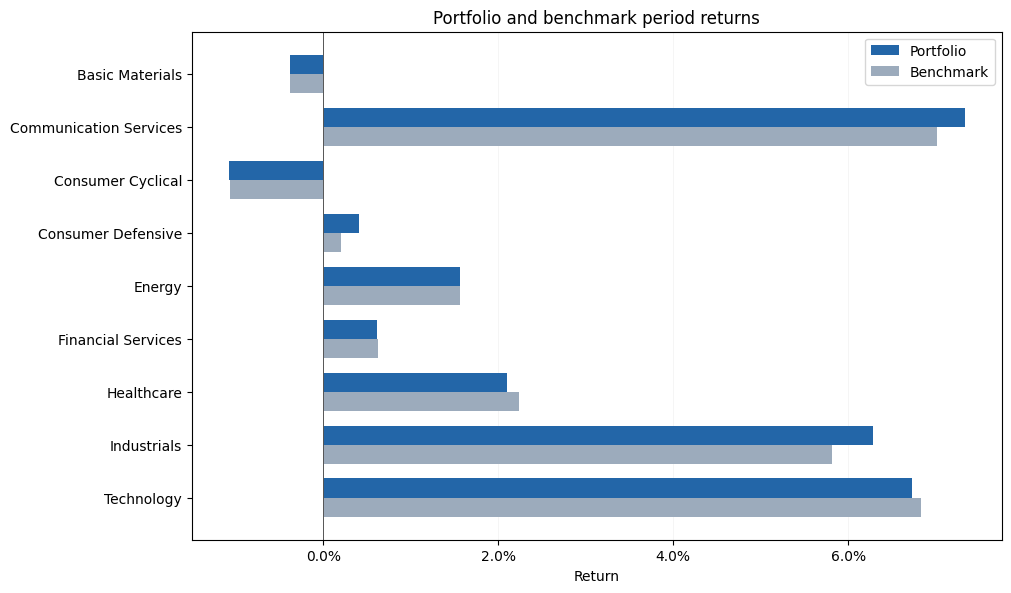

In [11]:
fig, ax = chart_single_period_category_returns(result, period=1)
plt.show()

## 11. Horizontal bars: weights

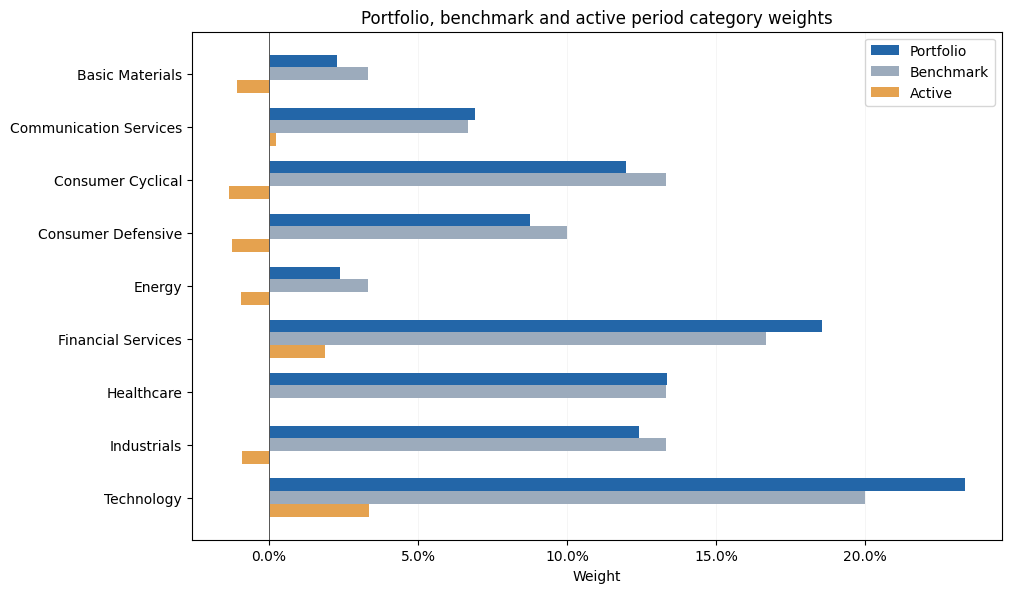

In [12]:
fig, ax = chart_single_period_category_weights(result, period=1)
plt.show()

## 12. Horizontal bars: attribution

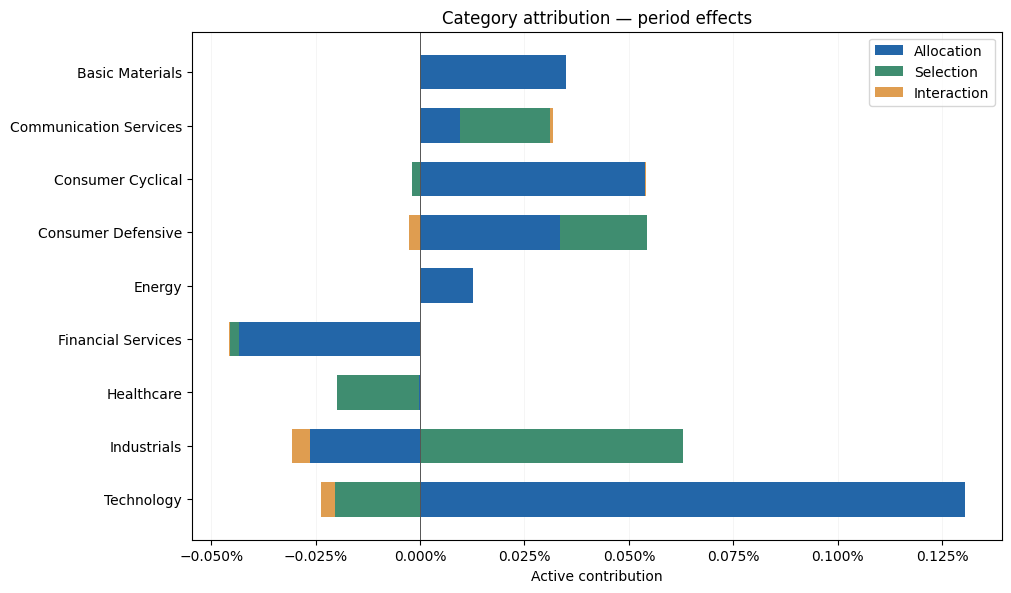

In [13]:
fig, ax = chart_single_period_category_attribution(result, period=1)
plt.show()

## 13. Excess-return waterfall

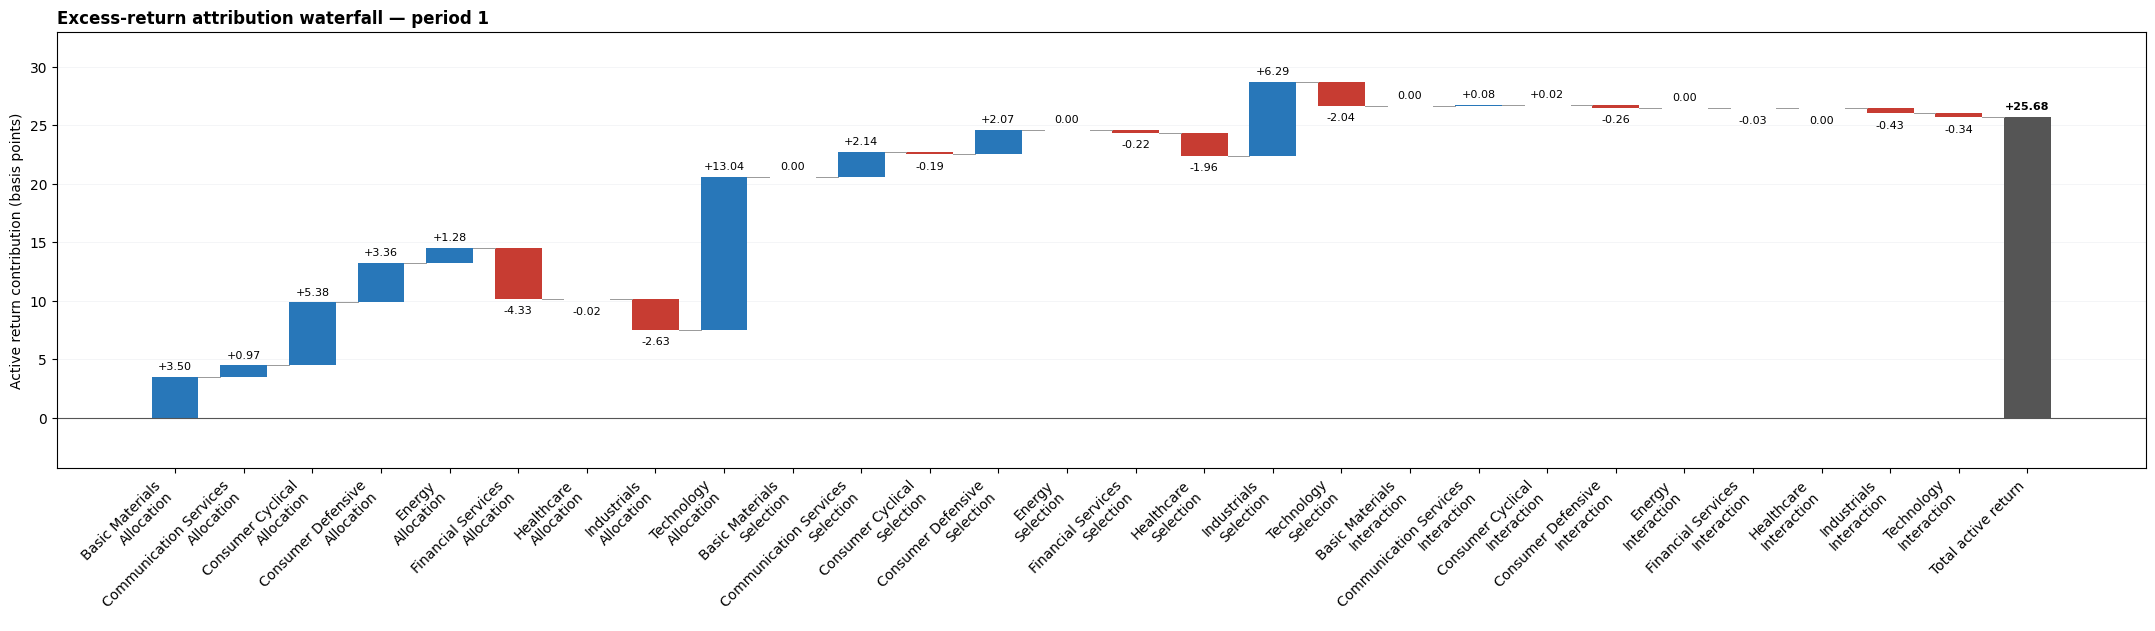

In [14]:
fig, ax = chart_single_period_excess_return_waterfall(result, period=1)
plt.show()

## 14. Explore another period interactively

Changing the slider **recalculates one selected period**; it never invokes a multi-period linker.

In [15]:
import ipywidgets as widgets
from IPython.display import display

def show_period(period):
    selected = calculate_single_period(sector, period=period, attribution=fachler,
                                       columns=column_names)
    print_single_period_category_weights(selected, period=period)
    print_single_period_category_attribution(selected, period=period)
    fig, ax = chart_single_period_category_attribution(selected, period=period)
    plt.show()

slider = widgets.IntSlider(value=1, min=int(periods["Period"].min()),
                           max=int(periods["Period"].max()), description="Period",
                           continuous_update=False)
output_widget = widgets.interactive_output(show_period, {"period": slider})
display(slider, output_widget)

IntSlider(value=1, continuous_update=False, description='Period', max=12, min=1)

Output()

The sector data and portfolio weights are illustrative. A single-period active return is an arithmetic difference; use the separate multiple-period tutorial for compounded-horizon attribution.